## Run this cell to download all data tables for cruises R/V Walton Smith 'WS', R/V Hogarth 'H', and R/V Savannah 'SAV' as part of SFER from the link below:

## https://www.ncei.noaa.gov/access/ocean-carbon-acidification-data-system/oceans/Coastal/Walton_Smith.html

## The code downloads the following datasets that must be removed from the subdirectory 'carbonate_data':
### 0154383_33WA20141201_GLODAP.csv
### 0157025_33WA20150921_GLODAP.csv
### 0309253_33WA2024-FC2409_Data_Final.csv

## DO NOT RUN IF DATA HAVE ALREADY BEEN DOWNLOADED

In [ ]:
import os
import re
import urllib.request

# Setup paths and request configuration
index_url = "https://www.ncei.noaa.gov/access/ocean-carbon-acidification-data-system/oceans/Coastal/Walton_Smith.html"
headers = {"User-Agent": "Mozilla/5.0"}
output_dir = "carbonate_data"
os.makedirs(output_dir, exist_ok=True)

# 1. Parse HTML index directly for matching vessel rows and extract Accession IDs
req = urllib.request.Request(index_url, headers=headers)
with urllib.request.urlopen(req) as resp:
    html = resp.read().decode("utf-8", errors="ignore")

rows = re.findall(r"<tr[^>]*>(.*?)</tr>", html, re.DOTALL | re.IGNORECASE)
accession_ids = set()

for row in rows:
    if re.search(r"Cruise\s+(WS|H|SAV)", row, re.I) or re.search(r"\b(WS|H|SAV)\d+", row, re.I):
        match = re.search(r"ocads/data/(\d{7})", row) or re.search(r"\b(0\d{6})\b", row)
        if match:
            accession_ids.add(match.group(1))

accession_ids = sorted(accession_ids)
print(f"Found {len(accession_ids)} Accession IDs. Starting downloads into './{output_dir}'...\n")

# 2. Download data files for each accession ID
for acc_id in accession_ids:
    dir_url = f"https://www.ncei.noaa.gov/data/oceans/ncei/ocads/data/{acc_id}/"
    try:
        with urllib.request.urlopen(urllib.request.Request(dir_url, headers=headers)) as resp:
            dir_html = resp.read().decode("utf-8", errors="ignore")

        # Find data files (.csv, .txt, .nc, .tsv, .xlsx) excluding manifest files
        files = re.findall(r'href="([^"]+\.(?:csv|txt|nc|tsv|xlsx))"', dir_html, re.I)
        data_files = [f for f in files if "manifest" not in f.lower() and not f.startswith("?")]

        for file_name in data_files:
            save_path = os.path.join(output_dir, f"{acc_id}_{file_name}")
            if os.path.exists(save_path):
                print(f"[{acc_id}] Exists: {file_name}")
                continue

            file_url = f"{dir_url}{file_name}"
            with urllib.request.urlopen(urllib.request.Request(file_url, headers=headers)) as f_resp, open(save_path, "wb") as out:
                out.write(f_resp.read())
            print(f"[{acc_id}] Downloaded: {file_name}")

    except Exception as e:
        print(f"[{acc_id}] Error: {e}")

## Inspect Column Headers

In [1]:
import os
import pandas as pd

# Iterate through files in 'carbonate_data' and inspect pH, DIC, and TA headers
print("=" * 85)
print(f"{'FILENAME':<35} | {'DIC HEADER':<12} | {'TA HEADER':<12} | {'pH 25°C HEADER':<15} | {'pH 20°C HEADER':<15}")
print("=" * 85)

if os.path.exists('carbonate_data'):
    for fname in sorted(os.listdir('carbonate_data')):
        if fname.endswith(('.csv', '.txt', '.tsv')):
            fpath = os.path.join('carbonate_data', fname)
            try:
                # Read only header row
                df_head = pd.read_csv(fpath, skiprows=lambda x: str(x).startswith(('#', '/')), nrows=1, low_memory=False)
                df_head.columns = df_head.columns.str.strip()
                cols = list(df_head.columns)

                # Match headers explicitly
                dic_h = next((c for c in cols if c in ['DIC_umol/kg', 'DIC', 'DIC_UMOL_KG', 'carbon_dic']), 'NONE')
                ta_h = next((c for c in cols if c in ['TA_umol/kg', 'TA', 'TA_UMOL_KG', 'carbon_ta']), 'NONE')
                ph25_h = next((c for c in cols if c in ['pH_TS_25C', 'pH25C', 'pH_25C', 'carbon_ph_25c']), 'NONE')
                ph20_h = next((c for c in cols if c in ['pH_TS_20C', 'pH20C', 'pH_20C', 'carbon_ph_20c']), 'NONE')
                
                # Check for generic pH if pH25 isn't explicitly named
                generic_ph = next((c for c in cols if c in ['PH_TOT', 'pH', 'pH_TOT'] and c not in [ph25_h, ph20_h]), None)
                if ph25_h == 'NONE' and generic_ph:
                    ph25_h = f"{generic_ph} (generic)"

                print(f"{fname:<35} | {dic_h:<12} | {ta_h:<12} | {ph25_h:<15} | {ph20_h:<15}")
            except Exception as e:
                print(f"{fname:<35} | ERROR READING FILE: {e}")
else:
    print("Directory 'carbonate_data' not found in working path.")

print("=" * 85)

FILENAME                            | DIC HEADER   | TA HEADER    | pH 25°C HEADER  | pH 20°C HEADER 
0154383_33WA20141201-WS1418_data.csv | DIC_umol/kg  | TA_umol/kg   | pH_TS_25C       | pH_TS_20C      
0154383_33WA20141201_GLODAP.csv     | NONE         | NONE         | NONE            | NONE           
0157025_33WA20150921-WS15264_data.csv | DIC_umol/kg  | TA_umol/kg   | pH_TS_25C       | pH_TS_20C      
0157025_33WA20150921_GLODAP.csv     | NONE         | NONE         | NONE            | NONE           
0188877_33WA20171009-WS17282_data.csv | DIC_umol/kg  | TA_umol/kg   | pH_TS_25C       | pH_TS_20C      
0188878_33WA20180430-WS18120_data.csv | DIC_umol/kg  | TA_umol/kg   | pH_TS_25C       | pH_TS_20C      
0188879_33WA20180806-WS18218_data.csv | DIC_umol/kg  | TA_umol/kg   | pH_TS_25C       | pH_TS_20C      
0188976_33WA20181012-WS18285_data.csv | DIC_umol/kg  | TA_umol/kg   | pH_TS_25C       | pH_TS_20C      
0188977_33WA20190128-WS19028_data.csv | DIC_umol/kg  | TA_umol/kg   | p

## Imports & Data Ingestion: Align by standardized and corrected station ID's and cruise ID's

In [2]:
import os
import re
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# 1. Define Mappings & Normalization Functions
# ---------------------------------------------------------
manual_cruise_map = {
    'H23138': 'HG23138',
    'H23314': 'HG23314',
    'SAV1803': 'SV18067',
    'WS1418': 'WS14335',
    'WS23061_SFER': 'WS23061'
}

def normalize_station(s):
    if pd.isna(s): return str(s)
    s = str(s).strip()
    
    manual_map = {
        '21': '21LK', '54b': '54', '55b': '55', '56b': '56',
        '57.1b': '57.1', '57.2b': '57.2', '57.3b': '57.3', '57b': '57'
    }
    for k, v in manual_map.items():
        if s.lower() == k.lower(): return v
        
    s = s.upper()
    s = re.sub(r'\.0$', '', s)
    s = re.sub(r'[\s\-/_]', '', s)
    return s

curated_file = "unique_stations.tsv"
norm_to_curated = {}
if os.path.exists(curated_file):
    df_curated = pd.read_csv(curated_file, sep='\t')
    curated_stations = set(df_curated['station'].dropna().astype(str).str.strip())
    norm_to_curated = {normalize_station(c): c for c in curated_stations}

def map_station(raw_station):
    raw_str = str(raw_station).strip()
    if raw_str in norm_to_curated.values(): return raw_str
    norm = normalize_station(raw_str)
    return norm_to_curated.get(norm, raw_str)

# Helper function to filter carbonate files by numeric depth
def filter_surface_numeric(df):
    depth_col = next((c for c in df.columns if str(c).strip().lower() in ['depth', 'depth_m', 'ctdprs', 'pressure']), None)
    if depth_col:
        df[depth_col] = pd.to_numeric(df[depth_col], errors='coerce')
        df = df[(df[depth_col] <= 2.5) | (df[depth_col].isna())].copy()
    return df

# ---------------------------------------------------------
# 2. Load & Clean SFER Data (Surface Only via depth_class)
# ---------------------------------------------------------
sfer_file = 'SFER_data.csv'
df_sfer = pd.DataFrame()

if os.path.exists(sfer_file):
    df_sfer = pd.read_csv(sfer_file, low_memory=False)
    
    c_col = next((c for c in df_sfer.columns if str(c).strip().lower() in ['cruise_id', 'cruiseid', 'cruise']), None)
    s_col = next((c for c in df_sfer.columns if str(c).strip().lower() in ['station_id', 'stationid', 'station']), None)
    
    if c_col: df_sfer = df_sfer.rename(columns={c_col: 'cruise_id'})
    if s_col: df_sfer = df_sfer.rename(columns={s_col: 'station_id'})
    
    if 'cruise_id' in df_sfer.columns:
        df_sfer['cruise_id'] = df_sfer['cruise_id'].astype(str).str.strip().map(lambda x: manual_cruise_map.get(x, x))
    if 'station_id' in df_sfer.columns:
        df_sfer['station_id'] = df_sfer['station_id'].apply(map_station)
        
    # Apply exact 'depth_class' filter for SFER
    if 'depth_class' in df_sfer.columns:
        df_sfer = df_sfer[df_sfer['depth_class'].astype(str).str.strip().str.lower() == 'surface'].copy()
        
    # Drop any remaining duplicates to enforce a 1-to-1 match
    df_sfer = df_sfer.drop_duplicates(subset=['cruise_id', 'station_id'], keep='first')

# ---------------------------------------------------------
# 3. Load & Clean Carbonate Data (Surface Only via numeric)
# ---------------------------------------------------------
carb_dir = 'carbonate_data'
carb_dfs = []

if os.path.exists(carb_dir):
    for fname in os.listdir(carb_dir):
        if fname.endswith(('.csv', '.txt', '.tsv')):
            filepath = os.path.join(carb_dir, fname)
            try:
                df_c = pd.read_csv(
                    filepath, 
                    skiprows=lambda x: str(x).startswith(('#', '/')), 
                    sep=None, 
                    engine='python'
                )
                
                c_col = next((c for c in df_c.columns if str(c).strip().lower() in ['cruise_id', 'cruiseid', 'cruise']), None)
                s_col = next((c for c in df_c.columns if str(c).strip().lower() in ['station_id', 'stationid', 'station']), None)
                
                if c_col: df_c = df_c.rename(columns={c_col: 'cruise_id'})
                if s_col: df_c = df_c.rename(columns={s_col: 'station_id'})
                
                if 'cruise_id' in df_c.columns:
                    df_c['cruise_id'] = df_c['cruise_id'].astype(str).str.strip()
                    df_c['cruise_id'] = df_c['cruise_id'].replace('nan', np.nan)
                    df_c['cruise_id'] = df_c['cruise_id'].map(lambda x: manual_cruise_map.get(x, x) if pd.notna(x) else x)
                
                if 'station_id' in df_c.columns:
                    df_c['station_id'] = df_c['station_id'].astype(str).str.strip()
                    df_c['station_id'] = df_c['station_id'].replace('nan', np.nan)
                    df_c['station_id'] = df_c['station_id'].apply(lambda x: map_station(x) if pd.notna(x) else x)
                
                # Apply numeric surface filter for carbonate files
                df_c = filter_surface_numeric(df_c)
                carb_dfs.append(df_c)
                
            except Exception as e:
                print(f"Error reading {fname}: {e}")

df_carb = pd.concat(carb_dfs, ignore_index=True) if carb_dfs else pd.DataFrame()

if not df_carb.empty:
    df_carb = df_carb.drop_duplicates(subset=['cruise_id', 'station_id'], keep='first')

# ---------------------------------------------------------
# 4. Perform the Merge
# ---------------------------------------------------------
if not df_sfer.empty and not df_carb.empty:
    df_merged = pd.merge(
        df_carb, 
        df_sfer, 
        on=['cruise_id', 'station_id'], 
        how='inner',
        suffixes=('_carb', '_sfer')
    )
    print(f"✅ Merge successful! 'df_merged' created with {len(df_merged)} purely SURFACE rows aligned.")
else:
    df_merged = pd.DataFrame()
    print("Error: Could not merge because one or both dataframes are empty.")

# ---------------------------------------------------------
# Subset df_merged to Requested Columns
# ---------------------------------------------------------

target_columns = [
    "cruise_id", "station_id", "year", "month", "day", "datetime", "lat_dec", "lon_dec", 
    "DIC_umol/kg", "DIC_Flag", "TA_umol/kg", "TA_Flag", "pH_TS_20C", "pH_TS_25C", "pH_Flag",
    "temp", "sal", "o2_ctd", "o2_disc", 
    "o2_disc_flag", "nh4", "nh4_flag", "po4", "po4_flag", "no3_no2", "no3_no2_flag", 
    "no3", "no3_flag", "no2", "no2_flag", "si", "si_flag", "chl", "chl_flag", "pheo", "pheo_flag"
]

# Strip any hidden whitespaces from the actual dataframe columns first
df_merged.columns = df_merged.columns.str.strip()

# Safely identify which of our target columns actually exist in the dataframe
existing_cols = [col for col in target_columns if col in df_merged.columns]
missing_cols = set(target_columns) - set(existing_cols)

# Apply the subset
df_merged = df_merged[existing_cols]

# Output the results
print(f"✅ Subset complete. 'df_merged' now contains {len(df_merged.columns)} columns.")

if missing_cols:
    print(f"\n⚠️ Note: The following {len(missing_cols)} columns were not found in the data and were skipped:")
    print(list(missing_cols))

print("\n--- First 5 Rows ---")
print(df_merged.head())

✅ Merge successful! 'df_merged' created with 1740 purely SURFACE rows aligned.
✅ Subset complete. 'df_merged' now contains 36 columns.

--- First 5 Rows ---
  cruise_id station_id  year  month  day             datetime  lat_dec  \
0   WS14335         54  2014     12    3  2014-12-03 14:46:00  25.3451   
1   WS14335         55  2014     12    3  2014-12-03 15:47:00  25.3500   
2   WS14335         56  2014     12    3  2014-12-03 16:22:00  25.3498   
3   WS14335         57  2014     12    3  2014-12-03 17:00:00  25.3522   
4   WS14335       57.1  2014     12    3  2014-12-03 17:49:00  25.3517   

   lon_dec  DIC_umol/kg  DIC_Flag  ...   no3  no3_flag   no2  no2_flag    si  \
0 -81.1521       2596.7       2.0  ...  0.27       NaN  0.13       NaN  31.8   
1 -81.1936       2320.0       2.0  ...  0.11       NaN  0.10       NaN  26.6   
2 -81.2289       2252.1       2.0  ...  0.02       NaN  0.07       NaN  24.8   
3 -81.2656       2166.6       2.0  ...  0.04       NaN  0.10       NaN  19.0  

## Verify that 'df_merged' was properly aligned with SFER_data.csv using 5 random rows

In [3]:
import pandas as pd
import numpy as np

# Ensure dataframes exist before running
if 'df_merged' in locals() and not df_merged.empty and 'df_sfer' in locals() and not df_sfer.empty:
    sample_size = min(5, len(df_merged))
    sample_df = df_merged.sample(n=sample_size)
    
    cols_to_check = ['sal', 'temp', 'nh4', 'chl']
    
    print(f"Verifying {sample_size} random matched rows...\n")
    
    for idx, row in sample_df.iterrows():
        c_id = row['cruise_id']
        s_id = row['station_id']
        
        print(f"--- Cruise: {c_id} | Station: {s_id} ---")
        
        # Locate the exact original row in df_sfer
        sfer_row = df_sfer[(df_sfer['cruise_id'] == c_id) & (df_sfer['station_id'] == s_id)]
        
        if sfer_row.empty:
            print("  [!] Error: Original row not found in df_sfer.\n")
            continue
            
        sfer_row = sfer_row.iloc[0]
        
        for col in cols_to_check:
            # Handle potential suffixes if the column existed in both dataframes prior to merging
            merged_col_name = f"{col}_sfer" if f"{col}_sfer" in df_merged.columns else col
            
            # Safely extract values
            val_merged = row.get(merged_col_name, np.nan)
            val_sfer = sfer_row.get(col, np.nan)
            
            # Check for match (handling NaN == NaN logic)
            is_match = (pd.isna(val_merged) and pd.isna(val_sfer)) or (val_merged == val_sfer)
            match_status = "✅ MATCH" if is_match else "❌ MISMATCH"
            
            print(f"  {col:>4}: df_merged = {str(val_merged):<10} | df_sfer = {str(val_sfer):<10} | {match_status}")
        print()

else:
    print("Error: 'df_merged' or 'df_sfer' is not defined or is empty. Please run the merge cell first.")

Verifying 5 random matched rows...

--- Cruise: WS24258 | Station: 68 ---
   sal: df_merged = 36.87      | df_sfer = 36.87      | ✅ MATCH
  temp: df_merged = 30.983     | df_sfer = 30.983     | ✅ MATCH
   nh4: df_merged = 0.0        | df_sfer = 0.0        | ✅ MATCH
   chl: df_merged = 3.509      | df_sfer = 3.509      | ✅ MATCH

--- Cruise: WS21212 | Station: 57 ---
   sal: df_merged = 36.086     | df_sfer = 36.086     | ✅ MATCH
  temp: df_merged = 30.705     | df_sfer = 30.705     | ✅ MATCH
   nh4: df_merged = 2.139      | df_sfer = 2.139      | ✅ MATCH
   chl: df_merged = nan        | df_sfer = nan        | ✅ MATCH

--- Cruise: HG26045 | Station: RP2 ---
   sal: df_merged = 35.7358    | df_sfer = 35.7358    | ✅ MATCH
  temp: df_merged = 17.9365    | df_sfer = 17.9365    | ✅ MATCH
   nh4: df_merged = 0.024      | df_sfer = 0.024      | ✅ MATCH
   chl: df_merged = 0.707      | df_sfer = 0.707      | ✅ MATCH

--- Cruise: WS20342 | Station: UKMID ---
   sal: df_merged = 36.151     | df_s

## Independently verify that 'df_merged' was properly aligned with SFER_data.csv using 5 random rows and comparing them to 'get_merged_data.csv'

In [4]:
import os
import pandas as pd
import numpy as np

ref_file = 'get_merged_data.csv'

# Ensure df_merged exists
if 'df_merged' in locals() and not df_merged.empty:
    if os.path.exists(ref_file):
        # 1. Load the independent reference dataset
        df_ref = pd.read_csv(ref_file, low_memory=False)
        
        # 2. Filter for surface samples only
        if 'sfer_depth' in df_ref.columns:
            df_ref['sfer_depth'] = pd.to_numeric(df_ref['sfer_depth'], errors='coerce')
            df_ref = df_ref[df_ref['sfer_depth'] == 0]
        
        # Standardize matching keys
        df_ref['sfer_cruise_id'] = df_ref['sfer_cruise_id'].astype(str).str.strip()
        df_ref['station_id'] = df_ref['station_id'].astype(str).str.strip()
        
        # Define the mapping between df_merged column names and get_merged_data.csv column names
        compare_map = {
            'temp': 'sfer_temp',
            'sal': 'sfer_sal',
            'nh4': 'sfer_nh4',
            'po4': 'sfer_po4'
        }
        
        # 3. Only sample from rows that overlap between the two datasets
        valid_cruises = df_ref['sfer_cruise_id'].unique()
        df_testable = df_merged[df_merged['cruise_id'].isin(valid_cruises)]
        
        if not df_testable.empty:
            sample_size = min(5, len(df_testable))
            sample_df = df_testable.sample(n=sample_size)
            
            print(f"Independently verifying {sample_size} random surface rows against '{ref_file}'...\n")
            
            for idx, row in sample_df.iterrows():
                c_id = str(row['cruise_id']).strip()
                s_id = str(row['station_id']).strip()
                
                print(f"--- Cruise: {c_id} | Station: {s_id} ---")
                
                # Locate the exact original row in get_merged_data.csv
                ref_row = df_ref[(df_ref['sfer_cruise_id'] == c_id) & (df_ref['station_id'] == s_id)]
                
                if ref_row.empty:
                    print("  [!] Error: Original row not found in get_merged_data.csv (depth=0).\n")
                    continue
                    
                ref_row = ref_row.iloc[0]
                
                for merged_base, ref_col in compare_map.items():
                    # Handle potential suffixes if the column existed in both dataframes prior to merging
                    merged_col_name = f"{merged_base}_sfer" if f"{merged_base}_sfer" in df_merged.columns else merged_base
                    
                    # Safely extract values
                    val_merged = row.get(merged_col_name, np.nan)
                    val_ref = ref_row.get(ref_col, np.nan)
                    
                    # Check for match (using 4 decimal rounding to avoid float precision errors)
                    try:
                        v_m = round(float(val_merged), 4)
                    except:
                        v_m = np.nan
                    try:
                        v_r = round(float(val_ref), 4)
                    except:
                        v_r = np.nan
                        
                    is_match = (pd.isna(v_m) and pd.isna(v_r)) or (v_m == v_r)
                    match_status = "✅ MATCH" if is_match else "❌ MISMATCH"
                    
                    print(f"  {merged_base:>4}: df_merged = {str(val_merged):<10} | get_merged = {str(val_ref):<10} | {match_status}")
                print()
        else:
            print(f"None of the cruises in df_merged overlap with {ref_file}.")
    else:
        print(f"Error: '{ref_file}' not found in the current directory.")
else:
    print("Error: 'df_merged' is not defined or is empty.")

Independently verifying 5 random surface rows against 'get_merged_data.csv'...

--- Cruise: HG25083 | Station: 65 ---
  temp: df_merged = 25.2402    | get_merged = 25.2402    | ✅ MATCH
   sal: df_merged = 34.2177    | get_merged = 34.2177    | ✅ MATCH
   nh4: df_merged = 0.6        | get_merged = 0.6        | ✅ MATCH
   po4: df_merged = 0.08       | get_merged = 0.08       | ✅ MATCH

--- Cruise: WS21212 | Station: V1 ---
  temp: df_merged = 30.636     | get_merged = 30.636     | ✅ MATCH
   sal: df_merged = 35.032     | get_merged = 35.032     | ✅ MATCH
   nh4: df_merged = 1.24       | get_merged = 1.24       | ✅ MATCH
   po4: df_merged = 0.096      | get_merged = 0.096      | ✅ MATCH

--- Cruise: WS22281 | Station: 16 ---
  temp: df_merged = 27.76      | get_merged = 27.76      | ✅ MATCH
   sal: df_merged = 35.692     | get_merged = 35.692     | ✅ MATCH
   nh4: df_merged = 0.36       | get_merged = 0.36       | ✅ MATCH
   po4: df_merged = 0.07       | get_merged = 0.07       | ✅ MATCH


## Identify carbonate parameters outliers using 3 SD method and remove them from df_merged

In [5]:
import numpy as np
import pandas as pd

# 1. Define columns to check
target_cols = ["DIC_umol/kg", "TA_umol/kg", "pH_TS_20C", "pH_TS_25C"]

# Ensure 'station_id' exists for grouping
group_col = 'station_id' if 'station_id' in df_merged.columns else 'station'

# 2. Create an empty DataFrame to store boolean outlier flags
df_outlier_flags = pd.DataFrame(index=df_merged.index)

print(f"--- Outlier Detection Summary (Per Station, 3 SD Method) ---")

for col in target_cols:
    if col in df_merged.columns:
        # Calculate mean and standard deviation per station
        col_mean = df_merged.groupby(group_col)[col].transform('mean')
        col_std = df_merged.groupby(group_col)[col].transform('std')
        
        # Calculate upper and lower bounds (3 SD)
        lower_bound = col_mean - (3 * col_std)
        upper_bound = col_mean + (3 * col_std)
        
        # Identify outliers (NaNs evaluate to False, protecting stations with n=1)
        is_outlier = (df_merged[col] < lower_bound) | (df_merged[col] > upper_bound)
        df_outlier_flags[f"{col}_outlier"] = is_outlier
        
        # Report summary
        total_valid = df_merged[col].notna().sum()
        outlier_count = is_outlier.sum()
        pct = (outlier_count / total_valid) * 100 if total_valid > 0 else 0
        
        print(f"{col: <15} : {outlier_count: >3} outliers flagged out of {total_valid: >4} valid records ({pct:.1f}%)")
    else:
        print(f"{col: <15} : Column not found in df_merged")

# # 3. Create a master mask for any row that has AT LEAST one outlier
# any_outlier_mask = df_outlier_flags.any(axis=1)

# print(f"\nTotal unique rows flagged for removal: {any_outlier_mask.sum()}")

# # 4. Remove the flagged rows from df_merged
# df_merged = df_merged[~any_outlier_mask].reset_index(drop=True)

# print(f"Updated df_merged shape: {df_merged.shape}")

--- Outlier Detection Summary (Per Station, 3 SD Method) ---
DIC_umol/kg     :   8 outliers flagged out of 1740 valid records (0.5%)
TA_umol/kg      :  16 outliers flagged out of 1740 valid records (0.9%)
pH_TS_20C       :  12 outliers flagged out of 1740 valid records (0.7%)
pH_TS_25C       :  12 outliers flagged out of 1740 valid records (0.7%)


##  Summary Table of Campaigns with K. brevis > 10,000 cells/L

In [6]:
import pandas as pd
from IPython.display import display

# ---------------------------------------------------------
# 1. Load FRESCA Data (combining all sheets)
# ---------------------------------------------------------
fresca_file = 'FRESCA 2024_2025 data_Final_Share.xlsx'
xls = pd.ExcelFile(fresca_file)

# Read all sheets and assign a 'campaign' column based on the sheet name
fresca_sheets = [
    pd.read_excel(xls, sheet_name=sheet).assign(campaign=sheet)
    for sheet in xls.sheet_names
]
df_fresca = pd.concat(fresca_sheets, ignore_index=True)

# Convert datetime column so we can extract year/month below
df_fresca['datetime (UTC)'] = pd.to_datetime(df_fresca['datetime (UTC)'], format='mixed', errors='coerce')

# Ensure date features and numeric cell count columns exist
df_fresca['year'] = df_fresca['datetime (UTC)'].dt.year
df_fresca['month'] = df_fresca['datetime (UTC)'].dt.month
df_fresca['K.brevis_count'] = pd.to_numeric(
    df_fresca['K.brevis total adhoc (cells/L)'], errors='coerce'
).fillna(0)

# Filter for sampling events exceeding 10,000 cells/L
bloom_threshold = 1000
df_blooms = df_fresca[df_fresca['K.brevis_count'] > bloom_threshold].copy()

# Group by Year and Month to aggregate statistics
bloom_summary = (
    df_blooms.groupby(['year', 'month'])
    .agg(
        bloom_samples=('K.brevis_count', 'count'),
        peak_cell_count=('K.brevis_count', 'max'),
        mean_cell_count=('K.brevis_count', 'mean'),
    )
    .reset_index()
)

# Format columns for display
bloom_summary['Year-Month'] = bloom_summary.apply(
    lambda r: f"{int(r['year'])}-{int(r['month']):02d}", axis=1
)
bloom_summary['Bloom Samples (>10k cells/L)'] = bloom_summary['bloom_samples'].map('{:,}'.format)
bloom_summary['Peak Cell Count (cells/L)'] = bloom_summary['peak_cell_count'].map('{:,.0f}'.format)
bloom_summary['Mean Cell Count (cells/L)'] = bloom_summary['mean_cell_count'].map('{:,.0f}'.format)

# Reorder and rename display columns
table_display = bloom_summary[
    [
        'Year-Month',
        'Bloom Samples (>10k cells/L)',
        'Peak Cell Count (cells/L)',
        'Mean Cell Count (cells/L)',
    ]
]

print(f"Summary of Campaigns with K. brevis > {bloom_threshold:,} cells/L:")
display(table_display)

Summary of Campaigns with K. brevis > 1,000 cells/L:


,Year-Month,Bloom Samples (>10k cells/L),Peak Cell Count (cells/L),Mean Cell Count (cells/L)
0,2022-10,9,"9,692","3,030"
1,2022-12,135,"1,274,405","88,945"
2,2023-01,128,"1,890,153","52,936"
3,2023-05,26,"4,177","1,611"
4,2024-09,32,"9,048","2,753"
5,2024-11,165,"849,151","48,202"
6,2025-01,157,"3,521,262","214,492"
7,2025-03,7,"1,788","1,279"


## Render K. brevis Spatial Map

/tmp/ipykernel_2476035/2301594102.py:102: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9).set_zorder(10)


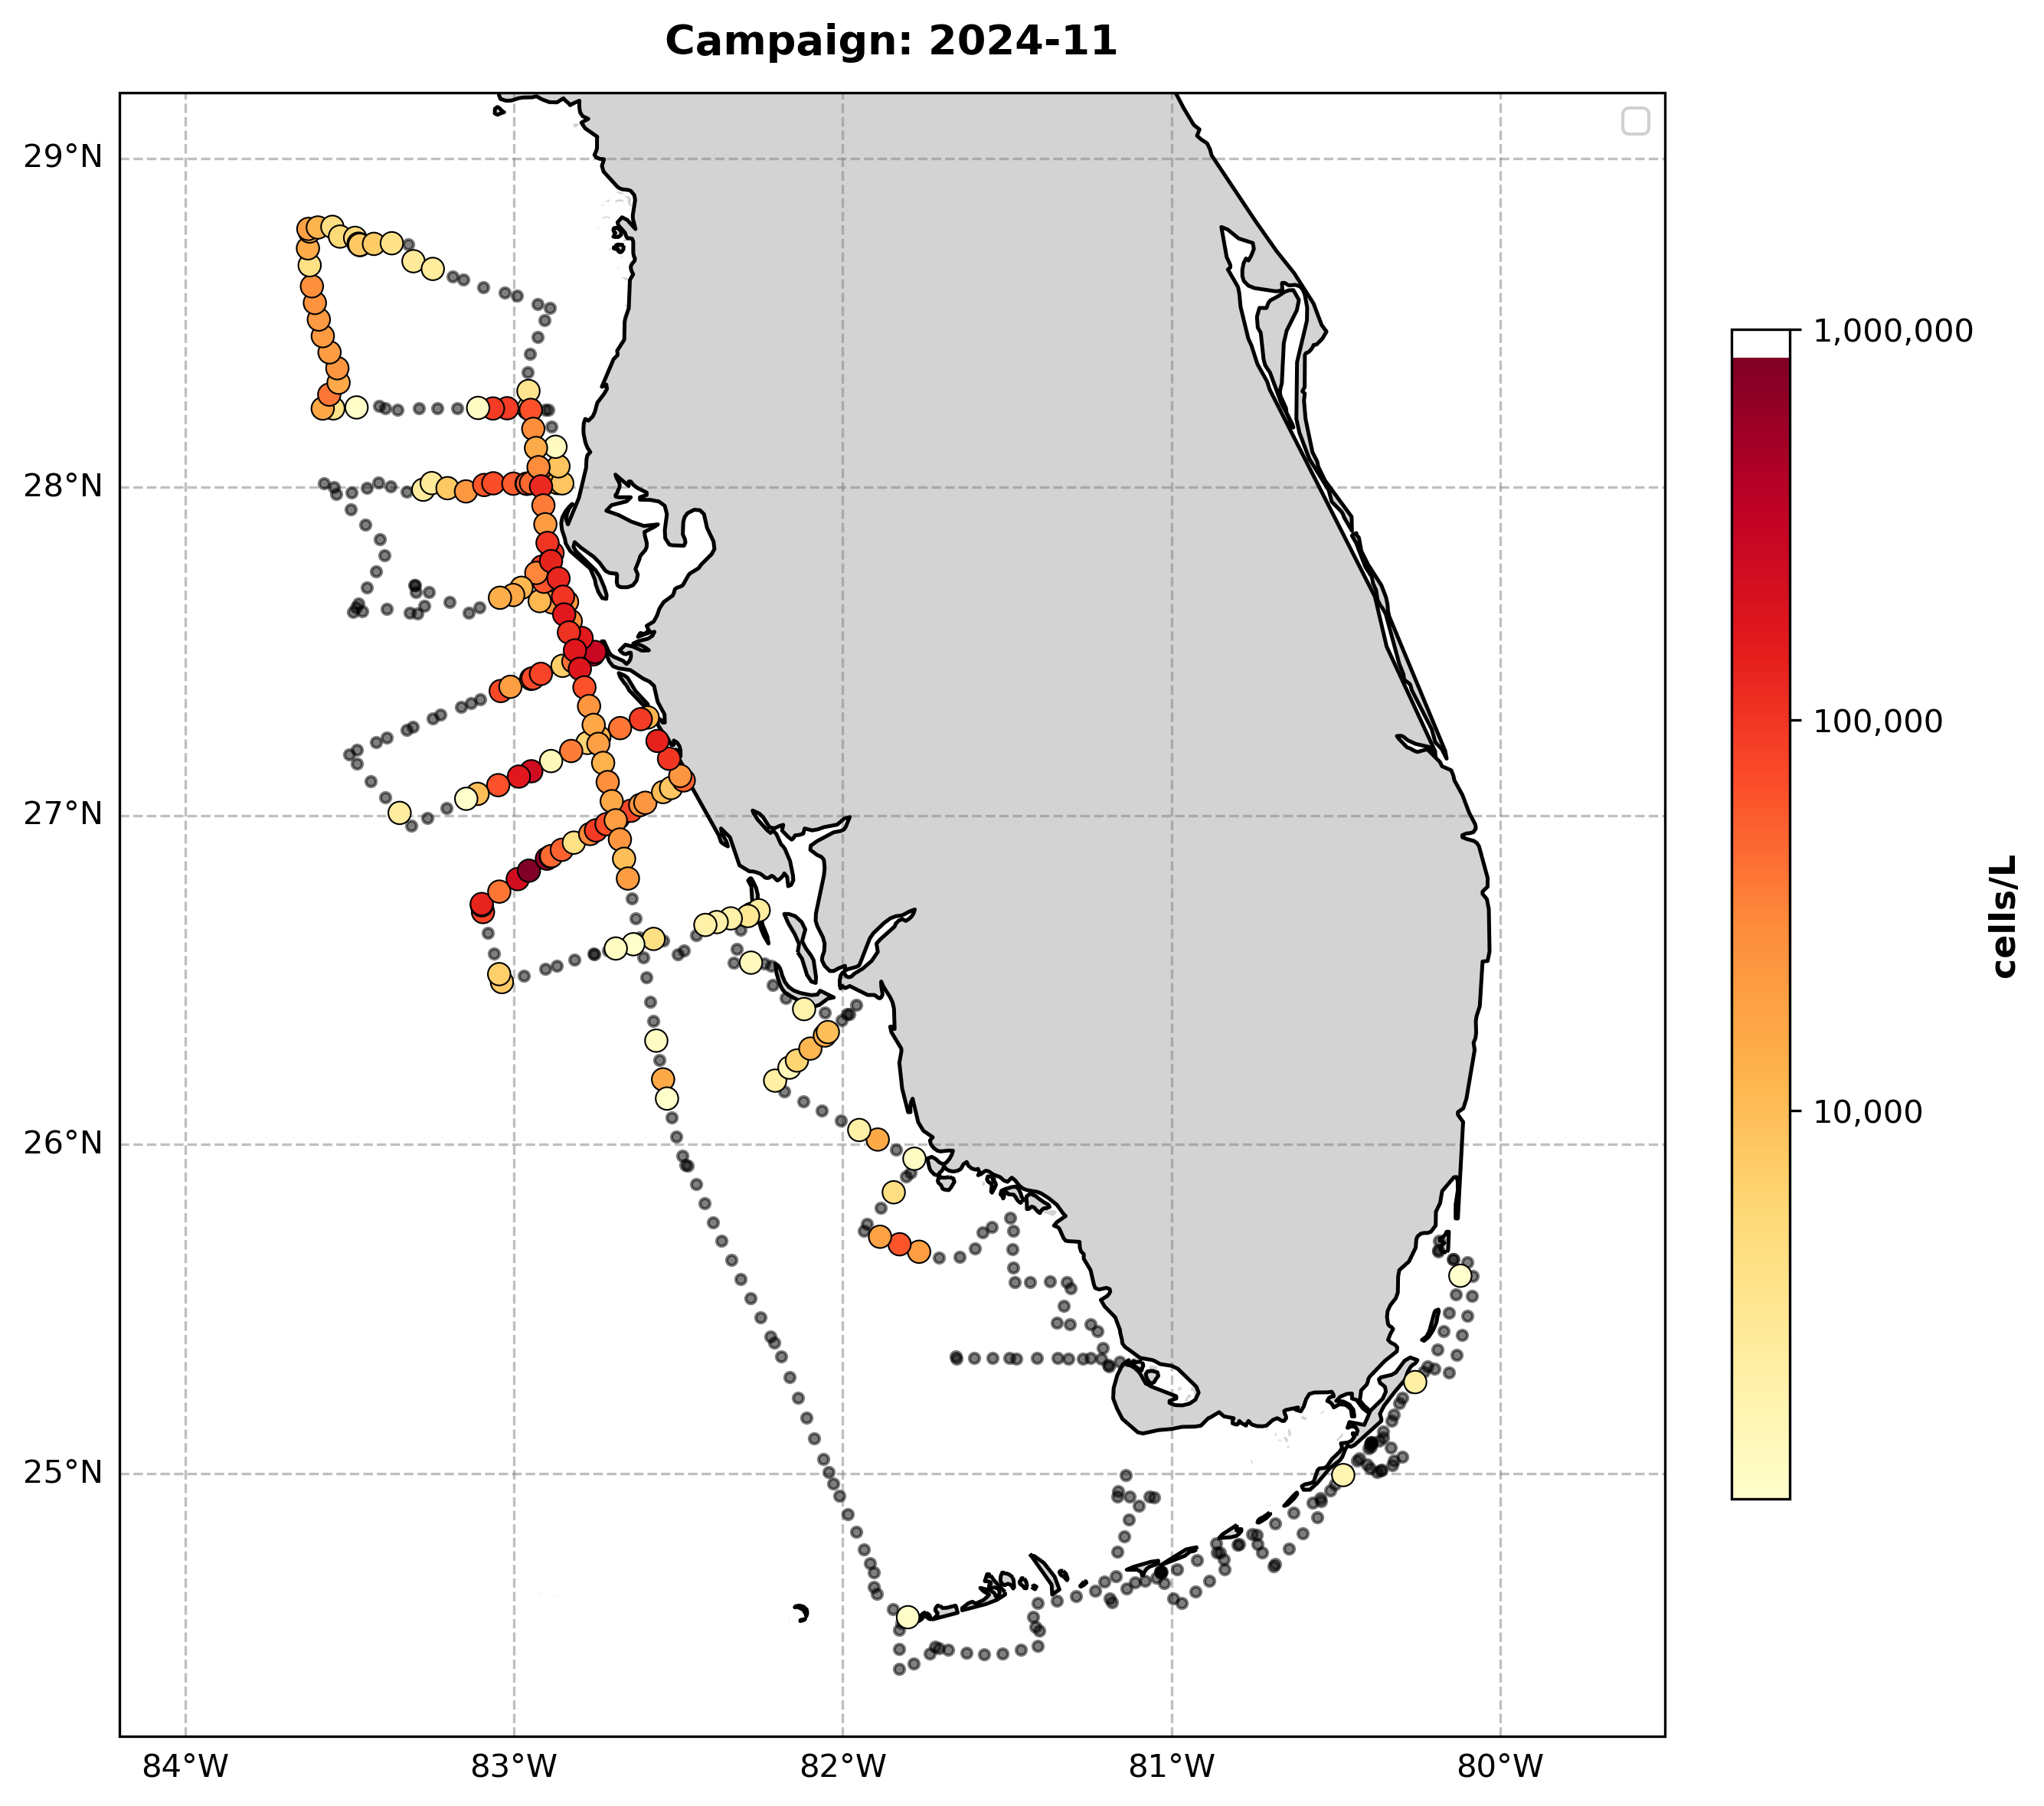

Campaign 2024-11 Summary:
 - Total IFCB Sampling Stations: 507
 - High-Density Detections (> 1,000 cells/L): 164
 - Peak K. brevis Density: 849,151 cells/L


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ------------------------------------------------------------------------------
# 1. User Inputs: Select Target Campaign Year and Month
# Available FRESCA campaigns: 2022-10, 2022-12, 2023-01, 2023-05, 
#                             2024-09, 2024-11, 2025-01, 2025-03
# ------------------------------------------------------------------------------
SELECTED_YEAR = 2024
SELECTED_MONTH = 11

# Cell count threshold for highlighting high-density bloom events (cells/L)
COUNT_THRESHOLD = 1000

# ------------------------------------------------------------------------------
# 2. Filter & Prepare Data
# ------------------------------------------------------------------------------
# Extract year and month from datetime if not already present
df_fresca['year'] = df_fresca['datetime (UTC)'].dt.year
df_fresca['month'] = df_fresca['datetime (UTC)'].dt.month

# Subset for target cruise campaign and drop missing coordinates
df_map = df_fresca[
    (df_fresca['year'] == SELECTED_YEAR) & 
    (df_fresca['month'] == SELECTED_MONTH)
].dropna(subset=['lat', 'lon']).copy()

# Ensure cell count column is numeric
df_map['K.brevis_count'] = pd.to_numeric(df_map['K.brevis total adhoc (cells/L)'], errors='coerce').fillna(0)

# Isolate high-count samples (> 10,000 cells/L) and calculate log10 values
df_bloom = df_map[df_map['K.brevis_count'] > COUNT_THRESHOLD].copy()
df_bloom['log10_count'] = np.log10(df_bloom['K.brevis_count'])

# ------------------------------------------------------------------------------
# 3. Setup Cartopy Map
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 10), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_extent([-84.2, -79.5, 24.2, 29.2], crs=ccrs.PlateCarree())

# Add Cartopy Features
ax.add_feature(cfeature.COASTLINE, linewidth=1.2, zorder=3)
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.6, zorder=3)

# Configure Gridlines
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, color='gray', zorder=5)
gl.top_labels = False
gl.right_labels = False

# ------------------------------------------------------------------------------
# 4. Plot Trajectory and Bloom Layers
# ------------------------------------------------------------------------------
# Layer 1: Cruise trajectory (All sampling locations)
ax.scatter(
    df_map['lon'], 
    df_map['lat'], 
    color='black', 
    s=10, 
    alpha=0.5, 
    transform=ccrs.PlateCarree(),
    zorder=4
)

# Layer 2: Bloom events (> 10,000 cells/L) color-coded by log10 count
if not df_bloom.empty:
    sc = ax.scatter(
        df_bloom['lon'], 
        df_bloom['lat'], 
        c=df_bloom['log10_count'], 
        s=50, 
        cmap='YlOrRd', 
        edgecolors='black', 
        linewidth=0.5, 
        transform=ccrs.PlateCarree(),
        zorder=6
    )
    
    # Add Colorbar
    cbar = plt.colorbar(sc, ax=ax, fraction=0.035, pad=0.04)
    cbar.set_label('cells/L', fontsize=11, fontweight='bold')
    
    # Set explicit ticks at log10 positions corresponding to 10k, 100k, and 1M
    tick_log_values = [4, 5, 6]
    cbar.set_ticks(tick_log_values)
    
    # Format labels as numbers with commas: 10,000, 100,000, 1,000,000
    cbar.set_ticklabels([f'{int(10**val):,}' for val in tick_log_values])

else:
    print(f"No sampling events with K. brevis > {COUNT_THRESHOLD:,} cells/L in {SELECTED_YEAR}-{SELECTED_MONTH:02d}.")

# Title & Legend
ax.set_title(
    f'Campaign: {SELECTED_YEAR}-{SELECTED_MONTH:02d}', 
    fontsize=13, 
    fontweight='bold', 
    pad=12
)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9).set_zorder(10)

plt.tight_layout()
plt.show()

# Print Campaign Summary
print(f"Campaign {SELECTED_YEAR}-{SELECTED_MONTH:02d} Summary:")
print(f" - Total IFCB Sampling Stations: {len(df_map)}")
print(f" - High-Density Detections (> {COUNT_THRESHOLD:,} cells/L): {len(df_bloom)}")
if not df_bloom.empty:
    print(f" - Peak K. brevis Density: {df_bloom['K.brevis_count'].max():,.0f} cells/L")

## Render DIC Concentration Map Matching K. brevis Detections

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ------------------------------------------------------------------------------
# 1. User Inputs
# ------------------------------------------------------------------------------
SELECTED_YEAR = 2025
SELECTED_MONTH = 1

# 'pH_TS_25C', 'DIC_umol/kg', or 'TA_umol/kg'
TARGET_PARAM = 'pH_TS_20C'  

PARAM_CONFIG = {
    'pH_TS_20C': {
        'col': 'pH_TS_20C',
        'name': 'Measured pH (20°C)',
        'cbar_label': 'pH',
        'cmap': 'coolwarm',
        'fmt': '%.2f',
        'vmin': 7.85, 
        'vmax': 8.20   
    },
    'pH_TS_25C': {
        'col': 'pH_TS_25C',
        'name': 'Measured pH (25°C)',
        'cbar_label': 'pH',
        'cmap': 'coolwarm',
        'fmt': '%.2f',
        'vmin': 7.85, 
        'vmax': 8.20   
    },
    'DIC_umol/kg': {
        'col': 'DIC_umol/kg',
        'name': 'Dissolved Inorganic Carbon (DIC)',
        'cbar_label': 'Dissolved Inorganic Carbon ($\mu$mol / kg)',
        'cmap': 'viridis',
        'fmt': '%.0f',
        'vmin': None,
        'vmax': None
    },
    'TA_umol/kg': {
        'col': 'TA_umol/kg',
        'name': 'Total Alkalinity (TA)',
        'cbar_label': 'Total Alkalinity ($\mu$mol / kg)',
        'cmap': 'plasma',
        'fmt': '%.0f',
        'vmin': None,
        'vmax': None
    }
}

cfg = PARAM_CONFIG[TARGET_PARAM]
param_col = cfg['col']

BLOOM_THRESHOLD = 1000
SPATIAL_TOLERANCE = 0.08

# ------------------------------------------------------------------------------
# 2. Prepare Data
# ------------------------------------------------------------------------------
# Filter df_merged using lat_dec and lon_dec
df_carb = df_merged[
    (df_merged['year'] == SELECTED_YEAR) & 
    (df_merged['month'] == SELECTED_MONTH)
].dropna(subset=['lat_dec', 'lon_dec', param_col]).copy()

# Filter FRESCA data
df_map = df_fresca[
    (df_fresca['year'] == SELECTED_YEAR) & 
    (df_fresca['month'] == SELECTED_MONTH)
].dropna(subset=['lat', 'lon']).copy()

df_blooms = df_map[df_map['K.brevis_count'] >= BLOOM_THRESHOLD].copy()

# Match spatial coincidence
df_carb['coincides_with_bloom'] = False
if not df_blooms.empty and not df_carb.empty:
    for idx, carb_row in df_carb.iterrows():
        distances = np.sqrt(
            (df_blooms['lat'] - carb_row['lat_dec']) ** 2 + 
            (df_blooms['lon'] - carb_row['lon_dec']) ** 2
        )
        if (distances < SPATIAL_TOLERANCE).any():
            df_carb.loc[idx, 'coincides_with_bloom'] = True

df_coincident_carb = df_carb[df_carb['coincides_with_bloom']].copy()

# ------------------------------------------------------------------------------
# 3. Setup Cartopy Map
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 10), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_extent([-84.2, -79.5, 24.2, 29.2], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE, linewidth=1.2, zorder=3)
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
ax.add_feature(cfeature.BORDERS, linestyle=':', alpha=0.6, zorder=3)

gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5, color='gray', zorder=5)
gl.top_labels = False
gl.right_labels = False

# ------------------------------------------------------------------------------
# 4. Plot Data Layers
# ------------------------------------------------------------------------------
ax.scatter(df_map['lon'], df_map['lat'], color='black', s=8, alpha=0.4, transform=ccrs.PlateCarree(), zorder=4)

if not df_carb.empty:
    sc_carb = ax.scatter(
        df_carb['lon_dec'], df_carb['lat_dec'], 
        c=df_carb[param_col], s=80, cmap=cfg['cmap'], 
        vmin=cfg['vmin'], vmax=cfg['vmax'], edgecolors='black', linewidth=0.6, 
        transform=ccrs.PlateCarree(), zorder=6
    )
    
    cbar = plt.colorbar(sc_carb, ax=ax, fraction=0.035, pad=0.04)
    cbar.set_label(cfg['cbar_label'], fontsize=11, fontweight='bold')
    cbar.formatter = ticker.FormatStrFormatter(cfg['fmt'])
    cbar.update_ticks()

if not df_coincident_carb.empty:
    ax.scatter(
        df_coincident_carb['lon_dec'], df_coincident_carb['lat_dec'], 
        facecolors='none', edgecolors='green', linewidth=2.0, s=180, 
        transform=ccrs.PlateCarree(), zorder=7
    )

ax.set_title(f'Campaign: {SELECTED_YEAR}-{SELECTED_MONTH:02d}', fontsize=13, fontweight='bold', pad=12)

# Create custom legend for clarity
# import matplotlib.lines as mlines
# circle_markers = mlines.Line2D([], [], color='green', marker='o', linestyle='None',
#                           markersize=12, fillstyle='none', markeredgewidth=2,
#                           label=f'Carbonate stations with K. brevis (\u2265 {BLOOM_THRESHOLD} cells/L)')
# black_dot = mlines.Line2D([], [], color='black', marker='o', linestyle='None',
#                           markersize=4, alpha=0.4, label='SFER Sampling Trajectory')
# ax.legend(handles=[circle_markers, black_dot], loc='upper right', frameon=True, facecolor='white', framealpha=0.9).set_zorder(10)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. Summary Output
# ------------------------------------------------------------------------------
print(f"Campaign {SELECTED_YEAR}-{SELECTED_MONTH:02d} Summary for [{cfg['name']}]:")
print(f" - Total Valid {TARGET_PARAM} Stations: {len(df_carb)}")
print(f" - Bloom Sampling Events (\u2265 {BLOOM_THRESHOLD:,} cells/L): {len(df_blooms)}")
print(f" - {TARGET_PARAM} Stations Coinciding with Blooms: {len(df_coincident_carb)}")

## Isolate Medium-High records by Bloom Stage 

In [ ]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# User Inputs: Early Bloom Campaigns & Spatial Settings
# ------------------------------------------------------------------------------
# TARGET_CAMPAIGNS = [(2023, 1), (2025, 1)]  
TARGET_CAMPAIGNS = [(2022, 12), (2024, 11)] 
TARGET_PARAM = "pH_TS_20C"                 
BLOOM_THRESHOLD = 1000
SPATIAL_TOLERANCE = 0.08                   # 0.05: ~5 km match radius / 0.08: ~8 km match radius

# ------------------------------------------------------------------------------
# Run Campaign-by-Campaign Diagnostic
# ------------------------------------------------------------------------------
total_coincident_stations = 0

for year, month in TARGET_CAMPAIGNS:
    # 1. Filter Carbonate Stations
    df_carb = df_merged[
        (df_merged["year"] == year) & (df_merged["month"] == month)
    ].dropna(subset=["lat_dec", "lon_dec", TARGET_PARAM])

    # 2. Filter FRESCA Bloom Events
    df_map = df_fresca[
        (df_fresca["year"] == year) & (df_fresca["month"] == month)
    ].dropna(subset=["lat", "lon"])
    
    df_blooms = df_map[df_map["K.brevis_count"] >= BLOOM_THRESHOLD]

    # 3. Spatial Coincidence Check
    n_coincident = 0
    if not df_blooms.empty and not df_carb.empty:
        for _, carb_row in df_carb.iterrows():
            dists = np.sqrt(
                (df_blooms["lat"] - carb_row["lat_dec"]) ** 2 + 
                (df_blooms["lon"] - carb_row["lon_dec"]) ** 2
            )
            if (dists < SPATIAL_TOLERANCE).any():
                n_coincident += 1

    total_coincident_stations += n_coincident

    print(
        f"Period [{year}-{month:02d}]: {len(df_carb)} Valid pH Stations | "
        f"{len(df_blooms)} Bloom Events | Coincident Red Circles = {n_coincident}"
    )

print("-" * 65)
print(f"✓ Total Combined Bloom Coincident Stations (Red Circles): {total_coincident_stations}")

## Carbonate System Parameter Distribution Across Bloom Categories

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ------------------------------------------------------------------------------
# 1. Configuration & Parameter Selection
# ------------------------------------------------------------------------------
# Choose from: "pH_TS_25C", "pH_TS_20C", "TA:DIC", or "DIC:TA"
TARGET_PARAM = "pH_TS_20C"  

# TARGET_CAMPAIGNS = [(2022, 12), (2024, 11)] 
TARGET_CAMPAIGNS = [(2023, 1), (2025, 1)]

# Ensure datetime exists
if "t_utc" not in df_merged.columns:
    df_merged["t_utc"] = pd.to_datetime(df_merged[["year", "month", "day"]])

# ------------------------------------------------------------------------------
# 2. Dynamic Target Parameter Preparation
# ------------------------------------------------------------------------------
# Explicitly define DIC and TA columns
dic_col = "DIC_umol/kg"
ta_col = "TA_umol/kg"

if TARGET_PARAM == "TA:DIC":
    df_merged["_target_val"] = df_merged[ta_col] / df_merged[dic_col]
    plot_label = "TA : DIC Ratio"
elif TARGET_PARAM == "DIC:TA":
    df_merged["_target_val"] = df_merged[dic_col] / df_merged[ta_col]
    plot_label = "DIC : TA Ratio"
else:
    df_merged["_target_val"] = df_merged[TARGET_PARAM]
    plot_label = TARGET_PARAM

# Categorize cells
def get_bloom_category(c):
    if c < 1000: return '1. Background\n(100–1k cells/L)'
    elif c < 10000: return '2. Low\n(1k–10k cells/L)'
    else: return '3. Medium-High\n(>10k cells/L)'

order = [
    '1. Background\n(100–1k cells/L)',
    '2. Low\n(1k–10k cells/L)',
    '3. Medium-High\n(>10k cells/L)'
]

# ------------------------------------------------------------------------------
# 3. Spatial-Temporal Matching
# ------------------------------------------------------------------------------
all_matched = []
for year, month in TARGET_CAMPAIGNS:
    df_c = df_merged[
        (df_merged["year"] == year) & (df_merged["month"] == month)
    ].dropna(subset=["lat_dec", "lon_dec", "_target_val"])
    
    df_b = df_fresca[
        (df_fresca["year"] == year) & (df_fresca["month"] == month)
    ].dropna(subset=["lat", "lon"])
    
    for _, c_row in df_c.iterrows():
        dists = np.sqrt((df_b["lat"] - c_row["lat_dec"])**2 + (df_b["lon"] - c_row["lon_dec"])**2)
        near = df_b[dists <= 0.08]
        
        if not near.empty:
            best_idx = (near["datetime (UTC)"] - c_row["t_utc"]).abs().idxmin()
            all_matched.append({
                "param_val": c_row["_target_val"],
                "temp": c_row.get("temp", np.nan),
                "category": get_bloom_category(near.loc[best_idx, "K.brevis_count"])
            })

df_plot = pd.DataFrame(all_matched)

# Filter out extreme low/erroneous values (e.g., negative ratios or zero)
df_plot = df_plot[df_plot["param_val"] > 0].copy()

# ------------------------------------------------------------------------------
# 4. Statistical Testing & Dynamic Plotting
# ------------------------------------------------------------------------------
groups = [df_plot[df_plot["category"] == cat]["param_val"].dropna() for cat in order]

# Pairwise Welch's t-tests (Robust to unequal sample size and unequal variance)
pairs = [(0, 1), (1, 2), (0, 2)]
p_vals = []
for i, j in pairs:
    # Welch's requires at least 2 observations per group to calculate variance
    if len(groups[i]) > 1 and len(groups[j]) > 1:
        
        # equal_var=False triggers Welch's t-test
        res = stats.ttest_ind(groups[i], groups[j], equal_var=False, nan_policy='omit')
        
        # Original Bonferroni correction (Note: if still 'ns', consider removing * len(pairs) for purely exploratory analysis)
        p_adj = min(res.pvalue * len(pairs), 1.0)
        
        star = '***' if p_adj < 0.001 else '**' if p_adj < 0.01 else '*' if p_adj < 0.05 else 'ns'
        p_vals.append((i, j, star))

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Boxplot
sns.boxplot(
    data=df_plot, x="category", y="param_val", order=order, ax=ax,
    color="lightgray", width=0.45, boxprops=dict(alpha=0.6), showfliers=False
)

# Overlay Scatter
cat_idx = df_plot["category"].map(order.index)
jitter = np.random.uniform(-0.12, 0.12, size=len(df_plot))
sc = ax.scatter(
    cat_idx + jitter, df_plot["param_val"], c=df_plot["temp"], cmap="plasma",
    vmin=15, vmax=30, s=60, edgecolors="black", lw=0.5, zorder=3
)
plt.colorbar(sc, ax=ax).set_label("Temperature (°C)", fontweight="bold")

# Dynamic Y-Axis Limits and Significance Bracket Stacking
y_min = df_plot["param_val"].min()
y_max = df_plot["param_val"].max()
y_range = y_max - y_min

# Set y-limits with padding for brackets
ax.set_ylim(y_min - 0.08 * y_range, y_max + 0.30 * y_range)

# Calculate dynamic bracket height offsets
bracket_step = 0.07 * y_range
bracket_tick = 0.015 * y_range

for idx_pair, (x1, x2, star) in enumerate(p_vals):
    h = y_max + (idx_pair + 1) * bracket_step
    ax.plot([x1, x1, x2, x2], [h - bracket_tick, h, h, h - bracket_tick], color="black", lw=1.2)
    ax.text((x1 + x2) / 2, h + (0.005 * y_range), star, ha="center", va="bottom", fontweight="bold")

campaign_str = ", ".join([f"{y}-{m:02d}" for y, m in TARGET_CAMPAIGNS])
ax.set(xlabel="", ylabel=plot_label)
ax.set_title(f'Late Bloom Stages: {campaign_str}', fontweight="bold")
ax.grid(True, ls="--", alpha=0.4, axis="y")

plt.tight_layout()
plt.show()

# Stats Printout
print(f"\n--- Mann-Whitney U Tests ({plot_label}) ---")
for x1, x2, star in p_vals:
    print(f"{order[x1].split()[1]} vs {order[x2].split()[1]}: {star}")

## Redundancy Analysis (RDA) Biplot for a specified bloom stage

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------------------------
# 1. Configuration & Campaign Setup
# ------------------------------------------------------------------------------
BLOOM_CAMPAIGNS = [(2022, 12), (2024, 11)]
# BLOOM_CAMPAIGNS = [(2023, 1), (2025, 1)]

# Safety check for timestamp column
if "t_utc" not in df_merged.columns:
  df_merged["t_utc"] = pd.to_datetime(df_merged[["year", "month", "day"]])

# ------------------------------------------------------------------------------
# 2. Extract & Spatial-Temporal Matching
# ------------------------------------------------------------------------------
matched_rows = []

for year, month in BLOOM_CAMPAIGNS:
  df_m = df_merged[
      (df_merged["year"] == year) & (df_merged["month"] == month)
  ].dropna(subset=["lat_dec", "lon_dec"])
  df_f = df_fresca[
      (df_fresca["year"] == year) & (df_fresca["month"] == month)
  ].dropna(subset=["lat", "lon"])

  for _, c_row in df_m.iterrows():
    dists = np.sqrt(
        (df_f["lat"] - c_row["lat_dec"]) ** 2
        + (df_f["lon"] - c_row["lon_dec"]) ** 2
    )
    near = df_f[dists <= 0.08]

    if not near.empty:
      blooms = near[near["K.brevis_count"] >= 10000]
      target_sub = blooms if not blooms.empty else near
      best_idx = (target_sub["datetime (UTC)"] - c_row["t_utc"]).abs().idxmin()

      r_dict = c_row.to_dict()
      r_dict["K.brevis_count"] = target_sub.loc[best_idx, "K.brevis_count"]
      matched_rows.append(r_dict)

df_ord = pd.DataFrame(matched_rows)

# ------------------------------------------------------------------------------
# 3. Categorization & Driver Matrix Preparation
# ------------------------------------------------------------------------------


def assign_stage(c):
  if c < 1000:
    return "Background (<1k)"
  elif c < 10000:
    return "Low (1k-10k)"
  else:
    return "Medium-High (>10k)"


df_ord["bloom_stage"] = df_ord["K.brevis_count"].apply(assign_stage)
df_ord["log_kbrevis"] = np.log10(
    df_ord["K.brevis_count"].astype(float).fillna(0) + 1.0
)

# Define Environmental Predictors (X) and Carbonate Responses (Y)
X_cols = [c for c in ["temp", "sal", "chl", "log_kbrevis"] if c in df_ord.columns]
Y_cols = [
    c
    for c in ["DIC_umol/kg", "TA_umol/kg", "pH_TS_20C"]
    if c in df_ord.columns
]

# Complete-case filtering & Z-score scaling
df_ord = df_ord.dropna(subset=X_cols + Y_cols).reset_index(drop=True)

X_scaled = StandardScaler().fit_transform(df_ord[X_cols])
Y_scaled = StandardScaler().fit_transform(df_ord[Y_cols])

# ------------------------------------------------------------------------------
# 4. Constrained RDA Multivariate Ordination
# ------------------------------------------------------------------------------
B_hat = np.linalg.pinv(X_scaled) @ Y_scaled
Y_hat = X_scaled @ B_hat

pca_rda = PCA(n_components=min(len(Y_cols), len(X_cols)))
Y_rda_scores = pca_rda.fit_transform(Y_hat)

total_var = np.sum(np.var(Y_scaled, axis=0))
constrained_var = np.sum(np.var(Y_hat, axis=0))
exp_var_ratio = pca_rda.explained_variance_ratio_ * (
    constrained_var / total_var
)

# ------------------------------------------------------------------------------
# 5. Render RDA Biplot
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
stage_colors = {
    "Background (<1k)": "navy",
    "Low (1k-10k)": "darkorange",
    "Medium-High (>10k)": "crimson",
}

# Plot station scores
for stage, color in stage_colors.items():
  idx = (df_ord["bloom_stage"] == stage).values
  if idx.any():
    ax.scatter(
        Y_rda_scores[idx, 0],
        Y_rda_scores[idx, 1],
        c=color,
        label=f"{stage} (n={idx.sum()})",
        s=60,
        alpha=0.8,
        edgecolors="black",
        lw=0.5,
    )

# Overlay Carbonate System Response Vectors (Y)
for i, col_name in enumerate(Y_cols):
  vec = pca_rda.components_[:, i] * 2.3
  ax.arrow(
      0,
      0,
      vec[0],
      vec[1],
      color="teal",
      head_width=0.08,
      linewidth=1.5,
      zorder=5,
  )
  ax.text(
      vec[0] * 1.15,
      vec[1] * 1.15,
      col_name.split("_")[0],
      color="teal",
      fontweight="bold",
      fontsize=10,
      ha="center",
  )

# Overlay Environmental Driver Vectors (X)
X_corr = (
    np.corrcoef(X_scaled.T, Y_rda_scores.T)[: len(X_cols), len(X_cols) :] * 2.0
)
x_labels = [
    "Temp" if "temp" in c else "Salinity" if "sal" in c else "Chl-a" if "chl" in c else "K.brevis"
    for c in X_cols
]

for i, label in enumerate(x_labels):
  ax.arrow(
      0,
      0,
      X_corr[i, 0],
      X_corr[i, 1],
      color="darkred",
      linestyle="--",
      head_width=0.08,
      linewidth=1.2,
      zorder=4,
  )
  ax.text(
      X_corr[i, 0] * 1.18,
      X_corr[i, 1] * 1.18,
      label,
      color="darkred",
      fontweight="bold",
      fontsize=9,
      ha="center",
  )

ax.set(
    xlim=(-2.5, 4.5),
    ylim=(-1.5, 2.5),
    xlabel=f"RDA Axis 1 ({exp_var_ratio[0]*100:.1f}% Constrained Var)",
    ylabel=f"RDA Axis 2 ({exp_var_ratio[1]*100:.1f}% Constrained Var)",
)
ax.set_title(
    "Early Bloom Stages", fontweight="bold"
)

ax.axhline(0, color="gray", linestyle=":", alpha=0.5)
ax.axvline(0, color="gray", linestyle=":", alpha=0.5)
ax.legend(
    title="Bloom Stage",
    loc="upper right",
    frameon=True,
    facecolor="white",
    framealpha=0.9,
)
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

# Print Summary
print(
    f"✓ RDA Complete: {len(df_ord)} Stations | Constrained Variance"
    f" Explained: {constrained_var / total_var * 100:.1f}%"
)

## Merge Cell Counts, Calculate CBPI Scores & Summary Statistics

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------------------------
# 1. Config & Datetime Formatting
# ------------------------------------------------------------------------------
if "t_utc" not in df_merged.columns:
    df_merged["t_utc"] = pd.to_datetime(df_merged[["year", "month", "day"]])
else:
    df_merged["t_utc"] = pd.to_datetime(df_merged["t_utc"], errors="coerce")

df_merged["year"] = df_merged["t_utc"].dt.year
df_merged["month"] = df_merged["t_utc"].dt.month

df_fresca["datetime_utc"] = pd.to_datetime(df_fresca["datetime (UTC)"], errors="coerce")
df_fresca["year"] = df_fresca["datetime_utc"].dt.year
df_fresca["month"] = df_fresca["datetime_utc"].dt.month

df_fresca["K.brevis_count"] = pd.to_numeric(
    df_fresca["K.brevis total adhoc (cells/L)"], errors="coerce"
).fillna(0)

# Auto-detect coordinate and response headers
lat_m = "lat_dec" if "lat_dec" in df_merged.columns else next(c for c in df_merged.columns if "lat" in c.lower())
lon_m = "lon_dec" if "lon_dec" in df_merged.columns else next(c for c in df_merged.columns if "lon" in c.lower())
lat_f = "lat" if "lat" in df_fresca.columns else next(c for c in df_fresca.columns if "lat" in c.lower())
lon_f = "lon" if "lon" in df_fresca.columns else next(c for c in df_fresca.columns if "lon" in c.lower())

possible_resp = ["pH_TS_20C", "DIC_umol/kg", "TA_umol/kg"]
response_cols = [c for c in possible_resp if c in df_merged.columns]

CAMPAIGN_STAGES = {
    (2022, 12): "Early Stage",
    (2024, 11): "Early Stage",
    (2023, 1): "Late Stage",
    (2025, 1): "Late Stage"
}

# ------------------------------------------------------------------------------
# 2. Campaign-Scoped Matching (Identical to RDA Pipeline)
# ------------------------------------------------------------------------------
matched_rows = []

for (year, month), stage_name in CAMPAIGN_STAGES.items():
    df_m_sub = df_merged[
        (df_merged["year"] == year) & (df_merged["month"] == month)
    ].dropna(subset=[lat_m, lon_m, "t_utc"] + response_cols).copy()
    
    df_f_sub = df_fresca[
        (df_fresca["year"] == year) & (df_fresca["month"] == month)
    ].dropna(subset=[lat_f, lon_f, "datetime_utc"]).copy()
    
    for _, carb_row in df_m_sub.iterrows():
        dist = np.sqrt(
            (df_f_sub[lat_f] - carb_row[lat_m]) ** 2 + 
            (df_f_sub[lon_f] - carb_row[lon_m]) ** 2
        )
        near = df_f_sub[dist <= 0.08]
        
        if not near.empty:
            best_idx = (near["datetime_utc"] - carb_row["t_utc"]).abs().idxmin()
            best_match = near.loc[best_idx]
            
            r_dict = carb_row.to_dict()
            r_dict["K.brevis_count"] = best_match["K.brevis_count"]
            r_dict["Stage"] = stage_name
            matched_rows.append(r_dict)

df_cbpi = pd.DataFrame(matched_rows)

# ------------------------------------------------------------------------------
# 3. Categorize Severity & Compute CBPI
# ------------------------------------------------------------------------------
def assign_severity(c):
    if c < 1000: return "Background (<1k)"
    elif c < 10000: return "Low (1k-10k)"
    else: return "Med-High (>10k)"

df_cbpi["Severity"] = df_cbpi["K.brevis_count"].apply(assign_severity)

# Compute Anomaly Z-Scores relative to Non-Bloom Baseline
bg_mask = df_cbpi["K.brevis_count"] < 100
bg_means = df_cbpi.loc[bg_mask, response_cols].mean()
bg_stds = df_cbpi.loc[bg_mask, response_cols].std().replace(0, 1)

Z_matrix = (df_cbpi[response_cols] - bg_means) / bg_stds

# Loadings from standardized chemical space
Y_chem = StandardScaler().fit_transform(df_cbpi[response_cols])
pca = PCA(n_components=min(2, len(response_cols)))
scores = pca.fit_transform(Y_chem)

rda2_loadings = [np.corrcoef(Y_chem[:, i], scores[:, 1])[0, 1] for i in range(len(response_cols))]
weights = pd.Series(rda2_loadings, index=response_cols)

df_cbpi["CBPI"] = (Z_matrix * weights).sum(axis=1)

# ------------------------------------------------------------------------------
# 4. Render Summary Table Output
# ------------------------------------------------------------------------------
cbpi_summary = (
    df_cbpi.groupby(["Stage", "Severity"])["CBPI"]
    .agg(
        Sample_Count="count",
        Mean_CBPI="mean",
        Median_CBPI="median",
        Std_Dev="std",
        Min_CBPI="min",
        Max_CBPI="max"
    )
    .reset_index()
)

# Logical sorting
stg_ord = {"Early Stage": 0, "Late Stage": 1}
sev_ord = {"Background (<1k)": 0, "Low (1k-10k)": 1, "Med-High (>10k)": 2}
cbpi_summary["stg_sort"] = cbpi_summary["Stage"].map(stg_ord)
cbpi_summary["sev_sort"] = cbpi_summary["Severity"].map(sev_ord)
cbpi_summary = cbpi_summary.sort_values(["stg_sort", "sev_sort"]).drop(columns=["stg_sort", "sev_sort"]).reset_index(drop=True)

print("=== Carbonate Bloom Perturbation Index (CBPI) Summary Statistics ===")
display(cbpi_summary.round(3))

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter extreme outliers
df_clean_cbpi = df_cbpi[df_cbpi['CBPI'].between(-3.0, 3.0)]

# Setup plot
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=300)

palette = {
    'Background (<1k)': '#2b83ba',
    'Low (1k-10k)': '#fdae61',
    'Med-High (>10k)': '#d7191c'
}

# CBPI Departures Plot
plot_kwargs = {
    'data': df_clean_cbpi, 'x': 'Stage', 'y': 'CBPI', 'hue': 'Severity',
    'order': ['Early Stage', 'Late Stage'],
    'hue_order': ['Background (<1k)', 'Low (1k-10k)', 'Med-High (>10k)'],
    'palette': palette, 'ax': ax
}

sns.boxplot(
    **plot_kwargs, width=0.5, showfliers=False,
    boxprops=dict(alpha=0.75, edgecolor='black'),
    medianprops=dict(color='black', linewidth=1.5)
)

sns.stripplot(
    **plot_kwargs, dodge=True, jitter=0.18, size=5, alpha=0.8,
    edgecolor='black', linewidth=0.5
)

# Reference baseline and formatting
ax.axhline(0.0, color='black', linestyle='--', linewidth=1.2, alpha=0.8)
ax.set_title('CBPI Departures from Non-Bloom Baseline', fontsize=12, fontweight='bold', pad=10)
ax.set_ylabel('CBPI Score (± Standardized Anomaly)', fontsize=10, fontweight='bold')
ax.set_xlabel('')
ax.set_ylim(-0.75, 0.75)
ax.grid(True, linestyle=':', alpha=0.5, axis='y')

# Clean Legend (Remove duplicate handles from stripplot)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:3], labels[:3], title='Bloom Severity', loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()